In [1]:
from typing import Annotated 
from typing_extensions import TypedDict 
from langchain_groq import ChatGroq
from langgraph.graph import START, END 
from langgraph.graph.state import StateGraph 
from langgraph.prebuilt import ToolNode 
from langgraph.graph.message import add_messages 
from langchain_core.tools import tool
from langchain_core.messages import BaseMessage 
import os
from dotenv import load_dotenv
load_dotenv() # To load our env variable

True

In [2]:
os.environ["LANGSMITH_PROJECT"] = "TestProject"

In [3]:
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["LANGSMITH_API_KEY"] = os.getenv("LANGCHAIN_API_KEY")
os.environ["LANGSMITH_TRACING"] = "true"

In [4]:
class State(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [5]:
from langchain.chat_models import init_chat_model
llm = init_chat_model("groq:openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001CD34264EC0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001CD34265BE0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
from langchain.tools import tool

@tool
def add(a:float, b:float):
    """Add two numbers. Use this tool every time the user asks to add, sum or total two numbers,
    even simple ones. Never do the addition yourself."""
    return a + b

tool_node = ToolNode([add])

llm_with_tool = llm.bind_tools([add])

def call_llm_model(state: State):
    return {"messages": [llm_with_tool.invoke(state['messages'])]}

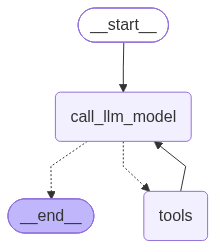

In [7]:
from langgraph.graph import START, END 
from langgraph.graph.state import StateGraph
from langgraph.prebuilt import tools_condition


builder = StateGraph(State)
builder.add_node("call_llm_model", call_llm_model)
builder.add_node("tools", tool_node)

builder.add_edge(START, "call_llm_model")
builder.add_conditional_edges(
    "call_llm_model",
    tools_condition
)
builder.add_edge("tools", "call_llm_model")

graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [8]:
response = graph.invoke({"messages":"What is 7 added to 20"})

In [9]:
response['messages'][-1].content

'7\u202f+\u202f20\u202f=\u202f27.'